### Ejercicio 7 (4 puntos)

Se considera el sistema de ecuaciones:

$$\begin{aligned}
y e^x - x^2 + 1 &= 0 \\
\cos(x) + \cos(y) - x &= 0
\end{aligned}$$

**a)** Escribir la matriz Jacobiana asociada al sistema no lineal.

**b)** Resolver el sistema no lineal usando el **Método de Newton** con aproximación inicial de $x^{(0)} = (2, 2)^T$ y una tolerancia de $10^{-9}$. Obtener la cantidad de iteraciones realizadas, el error y el comportamiento de la solución por cada iteración. Comparar estos resultados con el **método de Jarratt**, **Traub** y **Trapecio**.

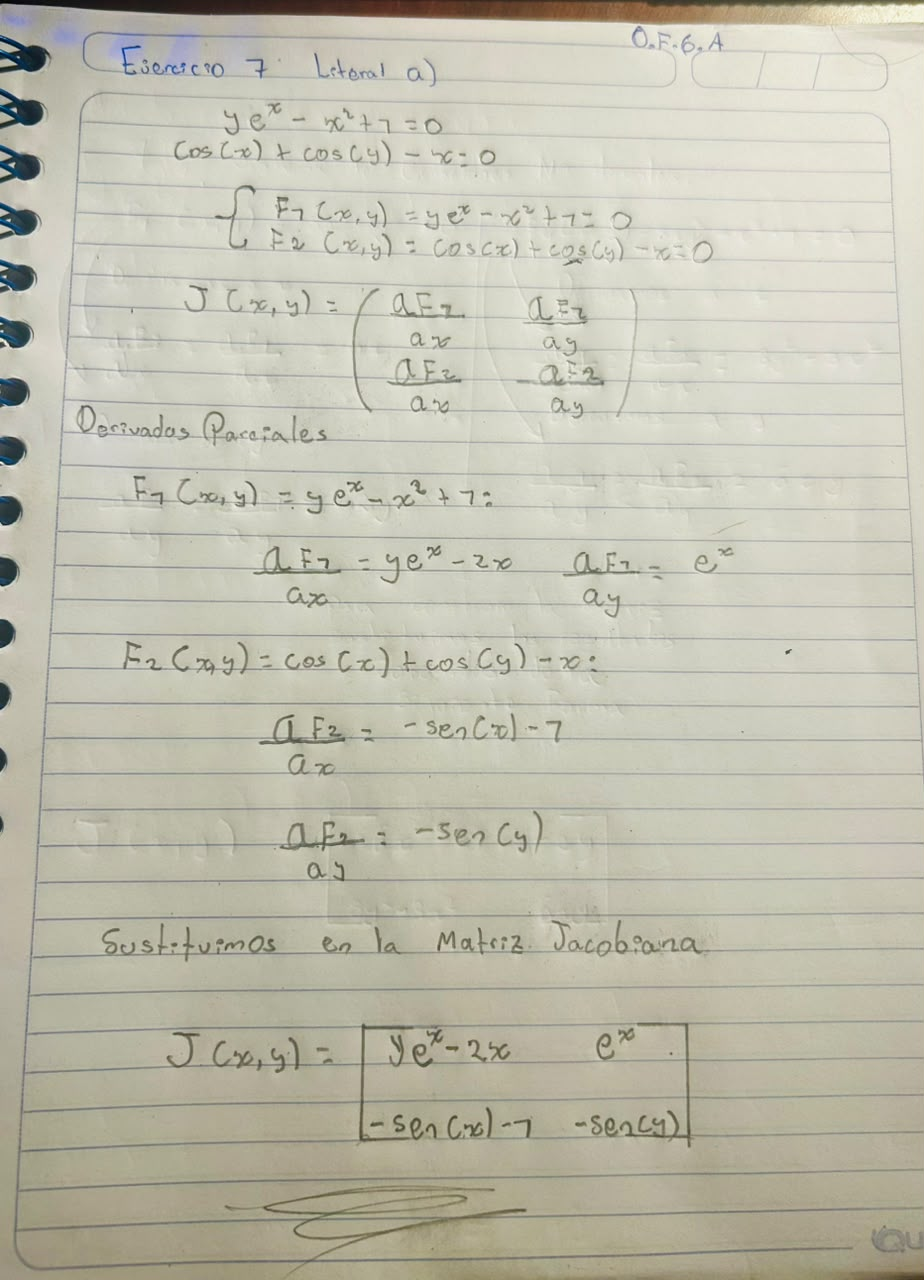

In [2]:
import numpy as np
import pandas as pd

# Formato de visualizacion a 16 decimales
pd.set_option('display.float_format', lambda x: '%.16f' % x)

# Definicion del sistema de ecuaciones F(x) y su Jacobiana JF(x)
F = lambda x: np.array([
    x[1] * np.exp(x[0]) - x[0]**2 + 1,
    np.cos(x[0]) + np.cos(x[1]) - x[0]
])

JF = lambda x: np.array([
    [x[1] * np.exp(x[0]) - 2 * x[0], np.exp(x[0])],
    [-np.sin(x[0]) - 1, -np.sin(x[1])]
])

# Parametros iniciales
x0 = np.array([2.0, 2.0])
tol = 1e-9
maxiter = 50

# 1. Metodo de Newton para sistemas
def newton_sys(F, JF, x0, tol, maxiter):
    x = x0.copy()
    iters = 0
    error = tol + 1
    x_hist, e_hist = [x.copy()], []

    while error > tol and iters < maxiter:
        s = np.linalg.solve(JF(x), -F(x))
        x_new = x + s

        error = np.linalg.norm(x_new - x, ord=np.inf)
        e_hist.append(error)
        x_hist.append(x_new.copy())
        iters += 1
        x = x_new

    return x, iters, error, x_hist, e_hist

# 2. Metodo de Traub para sistemas
def traub_sys(F, JF, x0, tol, maxiter):
    x = x0.copy()
    iters = 0
    error = tol + 1
    x_hist, e_hist = [x.copy()], []

    while error > tol and iters < maxiter:
        s1 = np.linalg.solve(JF(x), -F(x))
        y = x + s1
        s2 = np.linalg.solve(JF(x), -F(y))
        x_new = y + s2

        error = np.linalg.norm(x_new - x, ord=np.inf)
        e_hist.append(error)
        x_hist.append(x_new.copy())
        iters += 1
        x = x_new

    return x, iters, error, x_hist, e_hist

# 3. Metodo del Trapecio para sistemas
def trapecio_sys(F, JF, x0, tol, maxiter):
    x = x0.copy()
    iters = 0
    error = tol + 1
    x_hist, e_hist = [x.copy()], []

    while error > tol and iters < maxiter:
        s1 = np.linalg.solve(JF(x), -F(x))
        y = x + s1
        s_trap = np.linalg.solve(JF(x) + JF(y), 2 * F(x))
        x_new = x - s_trap

        error = np.linalg.norm(x_new - x, ord=np.inf)
        e_hist.append(error)
        x_hist.append(x_new.copy())
        iters += 1
        x = x_new

    return x, iters, error, x_hist, e_hist

# 4. Metodo de Jarratt para sistemas
def jarratt_sys(F, JF, x0, tol, maxiter):
    x = x0.copy()
    iters = 0
    error = tol + 1
    x_hist, e_hist = [x.copy()], []

    while error > tol and iters < maxiter:
        Jx = JF(x)
        s1 = np.linalg.solve(Jx, -F(x))
        y = x + (2.0 / 3.0) * s1

        Jy = JF(y)
        M = 3 * Jy - Jx
        N = 3 * Jy + Jx

        s2 = np.linalg.solve(M, N @ s1)
        x_new = x + 0.5 * s2

        error = np.linalg.norm(x_new - x, ord=np.inf)
        e_hist.append(error)
        x_hist.append(x_new.copy())
        iters += 1
        x = x_new

    return x, iters, error, x_hist, e_hist

# Ejecucion de los cuatro metodos
sol_n, it_n, err_n, x_h_n, e_h_n = newton_sys(F, JF, x0, tol, maxiter)
sol_tr, it_tr, err_tr, x_h_tr, e_h_tr = traub_sys(F, JF, x0, tol, maxiter)
sol_tp, it_tp, err_tp, x_h_tp, e_h_tp = trapecio_sys(F, JF, x0, tol, maxiter)
sol_j, it_j, err_j, x_h_j, e_h_j = jarratt_sys(F, JF, x0, tol, maxiter)

# Impresion de la comparativa
print("COMPARACIÓN DE MÉTODOS PARA SISTEMAS NO LINEALES ")
print(f"NEWTON   -> Solucion: {sol_n} | Iters: {it_n} | Error: {err_n:.16e}")
print(f"TRAUB    -> Solucion: {sol_tr} | Iters: {it_tr} | Error: {err_tr:.16e}")
print(f"TRAPECIO -> Solucion: {sol_tp} | Iters: {it_tp} | Error: {err_tp:.16e}")
print(f"JARRATT  -> Solucion: {sol_j} | Iters: {it_j} | Error: {err_j:.16e}")

# Tabla de seguimiento para Newton por iteracion
tabla_newton = pd.DataFrame({
    'Iteracion': list(range(1, it_n + 1)),
    'x_k': [x[0] for x in x_h_n[1:]],
    'y_k': [x[1] for x in x_h_n[1:]],
    'Error (||x_k - x_{k-1}||_inf)': e_h_n
})

print("\n SEGUIMIENTO DE NEWTON POR ITERACIÓN ")
print(tabla_newton.to_string(index=False))

COMPARACIÓN DE MÉTODOS PARA SISTEMAS NO LINEALES 
NEWTON   -> Solucion: [ -3.12240763 198.61234958] | Iters: 50 | Error: 1.8873508110733610e+00
TRAUB    -> Solucion: [1.27561443 0.17514926] | Iters: 5 | Error: 2.4176771695749721e-12
TRAPECIO -> Solucion: [   4.73059972 -111.42173319] | Iters: 50 | Error: 2.7221871720622147e+01
JARRATT  -> Solucion: [-2.6909588  92.01832861] | Iters: 50 | Error: 1.2041820410889557e+00

 SEGUIMIENTO DE NEWTON POR ITERACIÓN 
 Iteracion                  x_k                  y_k  Error (||x_k - x_{k-1}||_inf)
         1  -0.3722382308589420   3.8662921799156580             2.3722382308589420
         2  -1.0966971749944334   2.3336154458504543             1.5326767340652037
         3  -1.4303899878127346   3.5773397456500566             1.2437242997996023
         4  -1.2782039910500902   2.0082755159440824             1.5690642297059743
         5  -1.3674923294954719   3.2742815448172884             1.2660060288732060
         6  -1.0490333168268808  -1.